**STAT 453: Introduction to Deep Learning and Generative Models (Fall 2026)**

Instructor: Ben Lengerich

Course website: https://adaptinfer.org/dgm-fall-2026/

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AdaptInfer/dgm-fall-2026/blob/main/assets/hw/hw3/STAT453_hw03.ipynb)

## How to Submit

1. **Run every cell top to bottom before exporting**, so your output isn't stale:
   - Jupyter: `Kernel → Restart & Run All`
   - Colab: `Runtime → Restart and run all`
2. **Export this notebook to PDF or HTML:**
   - Colab: `File → Print → Save as PDF`
   - Local Jupyter: `File → Save and Export Notebook As → PDF`, or from a terminal: `jupyter nbconvert --to webpdf --allow-chromium-download STAT453_hw03.ipynb`
   - Local Jupyter: `File → Download As → HTML`
3. **Download the notebook:** — Download the final STAT453_hw03.ipynb and name the file `<netid>_hw3.ipynb`
4. **Check the PDF or HTML** — make sure plots aren't cut off at page edges and every cell that should have output actually shows it.
5. **Name the file `<netid>_hw3.pdf/<netid>_hw3.html`** (e.g. `lengerich_hw3.pdf`).
6. **Submit the PDF or HTML and ipynb on Canvas** by the deadline listed on the [homework page](https://adaptinfer.org/dgm-fall-2026/homework/).


# HW 3: Training Deep Nets Well — Optimizers, Initialization, Normalization, and Regularization (70 pts)

This assignment covers the toolkit that makes deep networks train reliably and generalize:

- **Part A (25 pts) — Optimizers:** SGD with momentum and Adam.
- **Part B (25 pts) — Initialization and normalization:** Xavier/He initialization and BatchNorm.
- **Part C (20 pts) — Regularization:** dropout, early stopping, and an L2 penalty.

Fill in the cells marked `# <your code>`. Each one is followed by a self-check; if it prints `looks good!`, you're on the right track (passing doesn't guarantee full credit). Cells marked **No modification required** are ungraded experiments. Everything runs on a CPU in about a minute.

**Due Sunday, November 1 at 11:59 PM. The homework assignment should be submitted via Canvas.**

See the submission checklist above. If you need help, come to office hours (times are on the [logistics page](https://adaptinfer.org/dgm-fall-2026/logistics/)) or contact the TA or the instructor.

## 0) Imports and data

**No modification required.** This downloads Fashion-MNIST (about 30 MB) and keeps a small training set of 1,000 images. To imitate the labeling mistakes real datasets have, it also replaces 30% of the *training* labels with random classes (validation and test labels stay correct). A small, noisy training set makes overfitting easy to see in Part C.

In [1]:
import math
import copy
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
%matplotlib inline

_ = torch.manual_seed(453)

In [2]:
fmnist_train = torchvision.datasets.FashionMNIST(root='./data', train=True, download=True)
fmnist_test = torchvision.datasets.FashionMNIST(root='./data', train=False, download=True)

def to_tensors(dataset, idx):
    return dataset.data[idx].float().view(len(idx), -1) / 255., dataset.targets[idx]

perm = torch.randperm(len(fmnist_train), generator=torch.Generator().manual_seed(453))
X_train, y_train = to_tensors(fmnist_train, perm[:1000])
X_val, y_val = to_tensors(fmnist_train, perm[1000:3000])
X_test, y_test = to_tensors(fmnist_test, torch.randperm(len(fmnist_test), generator=torch.Generator().manual_seed(453))[:2000])

g = torch.Generator().manual_seed(7)
noisy = torch.rand(len(y_train), generator=g) < 0.3                 # 30% of training labels...
y_train[noisy] = torch.randint(0, 10, (int(noisy.sum()),), generator=g)  # ...become random classes

mean, std = X_train.mean(), X_train.std()
X_train, X_val, X_test = [(X - mean) / std for X in (X_train, X_val, X_test)]
print('train', tuple(X_train.shape), '| val', tuple(X_val.shape), '| test', tuple(X_test.shape))

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.0MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 212kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.95MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 3.21MB/s]


train (1000, 784) | val (2000, 784) | test (2000, 784)


## Part A: Optimizers (25 pts)

Both optimizers take a list of parameter tensors and update them **in place** (`p -= ...`) when you call `step(grads)`, the same way `torch.optim` does.

### A.1) SGD with momentum (10 pts)

For each parameter $w$ with gradient $g_t$:

$$v_t = \beta\, v_{t-1} + g_t, \qquad w_t = w_{t-1} - \eta\, v_t, \qquad v_0 = 0$$

This is the form PyTorch uses. (Some texts average instead, $v_t = \beta v_{t-1} + (1-\beta) g_t$, which amounts to a different learning rate. Implement the form above.)

In [4]:
class MomentumSGD:
    def __init__(self, params, lr, beta=0.9):
        self.params, self.lr, self.beta = params, lr, beta
        self.v = [torch.zeros_like(p) for p in params]

    def step(self, grads):
        for i, (p, g) in enumerate(zip(self.params, grads)):
            self.v[i] = self.beta * self.v[i] + g
            p -= self.lr * self.v[i]

The self-check runs 20 steps of your optimizer and of `torch.optim` on the same small regression problem and compares the weights.

In [5]:
g = torch.Generator().manual_seed(0)
Xr, Yr = torch.randn(20, 2, generator=g), torch.randn(20, 3, generator=g)
W0, b0 = torch.randn(3, 2, generator=g), torch.randn(3, generator=g)

def regression_loss(W, b):
    return ((Xr @ W.T + b - Yr) ** 2).mean()

def grads_of(params):
    leaves = [p.detach().clone().requires_grad_(True) for p in params]
    regression_loss(*leaves).backward()
    return [leaf.grad for leaf in leaves]

def matches_torch(my_opt_cls, torch_opt_cls, my_kwargs, torch_kwargs, steps=20):
    mine = [W0.clone(), b0.clone()]
    my_opt = my_opt_cls(mine, **my_kwargs)
    ref = [W0.clone().requires_grad_(True), b0.clone().requires_grad_(True)]
    ref_opt = torch_opt_cls(ref, **torch_kwargs)
    for _ in range(steps):
        my_opt.step(grads_of(mine))
        ref_opt.zero_grad()
        regression_loss(*ref).backward()
        ref_opt.step()
    return all(torch.allclose(a, b.detach(), atol=1e-5) for a, b in zip(mine, ref))

assert matches_torch(MomentumSGD, torch.optim.SGD, dict(lr=0.05, beta=0.9), dict(lr=0.05, momentum=0.9)), \
    "MomentumSGD doesn't match torch.optim.SGD(momentum=0.9)"
print('looks good!')

looks good!


### A.2) Adam (15 pts)

Adam (Kingma & Ba, 2014) keeps running averages of the gradient ($m_t$) and of the squared gradient ($r_t$), corrects both for starting at zero, and divides each coordinate's step by that coordinate's recent gradient size:

$$m_t = \beta_1 m_{t-1} + (1-\beta_1)\, g_t, \qquad r_t = \beta_2 r_{t-1} + (1-\beta_2)\, g_t^2$$

$$\hat m_t = \frac{m_t}{1-\beta_1^t}, \qquad \hat r_t = \frac{r_t}{1-\beta_2^t}, \qquad w_t = w_{t-1} - \eta\, \frac{\hat m_t}{\sqrt{\hat r_t} + \epsilon}$$

with $m_0 = r_0 = 0$ and $t$ counting from 1. All operations are elementwise.

In [6]:
class Adam:
    def __init__(self, params, lr=1e-3, beta1=0.9, beta2=0.999, eps=1e-8):
        self.params = params
        self.lr, self.beta1, self.beta2, self.eps = lr, beta1, beta2, eps
        self.m = [torch.zeros_like(p) for p in params]
        self.r = [torch.zeros_like(p) for p in params]
        self.t = 0

    def step(self, grads):
        self.t += 1
        for i, (p, g) in enumerate(zip(self.params, grads)):
            self.m[i] = self.beta1 * self.m[i] + (1 - self.beta1) * g
            self.r[i] = self.beta2 * self.r[i] + (1 - self.beta2) * g**2
            m_hat = self.m[i] / (1 - self.beta1**self.t)
            r_hat = self.r[i] / (1 - self.beta2**self.t)
            p -= self.lr * m_hat / (torch.sqrt(r_hat) + self.eps)

In [7]:
assert matches_torch(Adam, torch.optim.Adam, dict(lr=0.05), dict(lr=0.05)), "Adam doesn't match torch.optim.Adam"
print('looks good!')

looks good!


### A.3) Race on an ill-conditioned bowl

**No modification required.** Watch your optimizers minimize $f(w) = \tfrac12(w_1^2 + 50 w_2^2)$, a bowl 50× steeper along $w_2$. It turns out that plain GD (momentum with `beta=0`) only converges for learning rates below $2/50 = 0.04$, so watch it run just below and just above that limit.

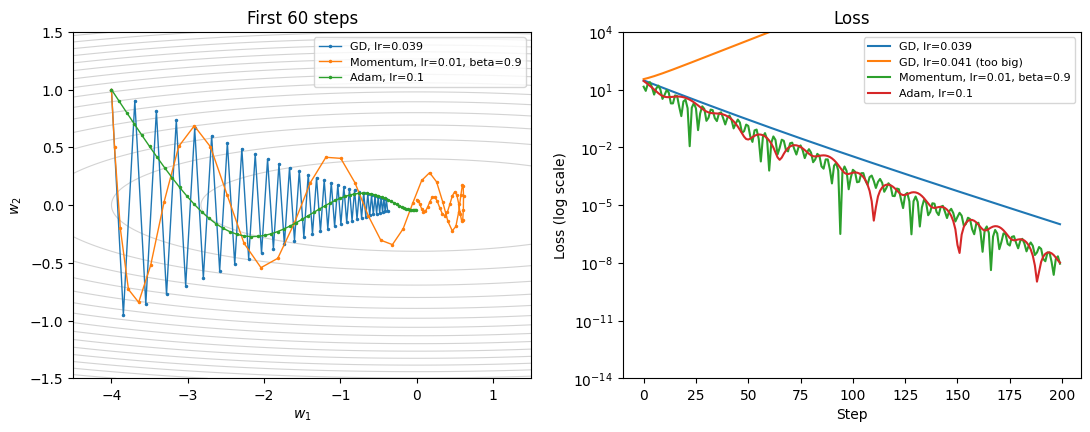

In [8]:
lam = torch.tensor([1.0, 50.0])

def run_optimizer(make_opt, steps=200):
    w = torch.tensor([-4.0, 1.0])
    opt = make_opt([w])
    path, losses = [w.clone()], []
    for _ in range(steps):
        opt.step([lam * w])                      # exact gradient of f
        path.append(w.clone())
        losses.append(0.5 * (lam * w ** 2).sum().item())
    return torch.stack(path), losses

runs = {
    'GD, lr=0.039':                lambda p: MomentumSGD(p, lr=0.039, beta=0.0),
    'GD, lr=0.041 (too big)':      lambda p: MomentumSGD(p, lr=0.041, beta=0.0),
    'Momentum, lr=0.01, beta=0.9': lambda p: MomentumSGD(p, lr=0.01, beta=0.9),
    'Adam, lr=0.1':                lambda p: Adam(p, lr=0.1),
}
results = {name: run_optimizer(make) for name, make in runs.items()}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
w1g, w2g = torch.meshgrid(torch.linspace(-4.5, 1.5, 200), torch.linspace(-1.5, 1.5, 200), indexing='ij')
ax1.contour(w1g, w2g, 0.5 * (w1g ** 2 + 50 * w2g ** 2), levels=20, colors='lightgray', linewidths=0.8)
for name, (path, losses) in results.items():
    if 'too big' not in name:                    # the diverging run leaves the plot
        ax1.plot(path[:60, 0], path[:60, 1], '.-', ms=3, lw=1, label=name)
    ax2.semilogy([max(l, 1e-16) for l in losses], label=name)
ax1.set(xlabel='$w_1$', ylabel='$w_2$', title='First 60 steps', xlim=(-4.5, 1.5), ylim=(-1.5, 1.5))
ax2.set(xlabel='Step', ylabel='Loss (log scale)', title='Loss', ylim=(1e-14, 1e4))
ax1.legend(fontsize=8); ax2.legend(fontsize=8)
plt.show()

**What this should show:**
- **`GD, lr=0.039`:** in the left plot, the path zig-zags up and down across the narrow valley while creeping slowly toward the minimum at (0, 0). The steep $w_2$ direction limits how big the learning rate can be, which leaves the steps along the flat $w_1$ direction tiny.
- **`GD, lr=0.041 (too big)`:** in the right plot, the loss shoots *up*. Just past $0.04$, every step overshoots along $w_2$ by more than it corrects.
- **`Momentum`:** reaches a low loss in fewer steps than GD despite a 4× smaller learning rate. Along $w_1$ every gradient points the same way, so the velocity keeps growing (up to 10× a single gradient when $\beta = 0.9$). Along $w_2$ the gradient flips sign every step, so the velocity there cancels out.
- **`Adam`:** curves smoothly toward the minimum instead of zig-zagging. It divides each coordinate's step by that coordinate's typical gradient size, so the steep and flat directions move at about the same speed.

## Part B: Initialization and Normalization (25 pts)

### B.1) Xavier and He initialization (10 pts)

Complete `init_linear_()` so it fills an `nn.Linear` layer's weights from $\mathcal{N}(0, \sigma^2)$ and sets its biases to zero. The code sets `std`, the **standard deviation** $\sigma$:

| scheme | variance $\sigma^2$ |
|---|---|
| `'small'` | $0.01^2$ |
| `'xavier'` | $\frac{2}{\text{fan}_\text{in} + \text{fan}_\text{out}}$ |
| `'he'` | $\frac{2}{\text{fan}_\text{in}}$ |

`nn.Linear(in, out).weight` has shape `(out, in)`.

In [9]:
def init_linear_(layer, scheme):
    fan_out, fan_in = layer.weight.shape
    if scheme == 'small':
        std = 0.01
    elif scheme == 'xavier':
        std = math.sqrt(2.0 / (fan_in + fan_out))
    elif scheme == 'he':
        std = math.sqrt(2.0 / fan_in)
    else:
        raise ValueError(scheme)
    with torch.no_grad():
        layer.weight.normal_(0.0, std)
        layer.bias.zero_()
    return layer

In [10]:
torch.manual_seed(0)
big = nn.Linear(2000, 1000)
init_linear_(big, 'xavier')
assert abs(big.weight.std().item() - math.sqrt(2 / 3000)) < 1e-3, "xavier std looks wrong"
assert torch.all(big.bias == 0), "biases should be zero"
init_linear_(big, 'he')
assert abs(big.weight.std().item() - math.sqrt(2 / 2000)) < 1e-3, "he std looks wrong (check fan_in vs fan_out)"
assert abs(init_linear_(nn.Linear(2000, 1000), 'small').weight.std().item() - 0.01) < 1e-3
print('looks good!')

looks good!


### B.2) BatchNorm, training and eval mode (15 pts)

Complete `MyBatchNorm1d.forward()` for input `x` of shape `(batch, features)`.

**Training mode:** normalize each feature with the current batch's mean and (biased) variance, then scale and shift:
$$\hat x = \frac{x - \mu_B}{\sqrt{\sigma_B^2 + \epsilon}}, \qquad y = \gamma \hat x + \beta$$
Also update the running averages: `running_mean = (1 - momentum) * running_mean + momentum * mu_B` (this `momentum` is just the averaging weight, unrelated to optimizer momentum), and the same for `running_var`, except that, like PyTorch, it blends in the *unbiased* variance $\frac{n}{n-1}\sigma_B^2$.

**Eval mode:** normalize with `running_mean` and `running_var` instead, and don't update anything.

In the code, $\mu_B$ and $\sigma_B^2$ are `mu` and `var`, and $\gamma$ and $\beta$ (the learned scale and shift, unrelated to Part A's $\beta$) are `self.gamma` and `self.beta`.

In [11]:
class MyBatchNorm1d:
    def __init__(self, num_features, eps=1e-5, momentum=0.1):
        self.eps, self.momentum = eps, momentum
        self.gamma = torch.ones(num_features)
        self.beta = torch.zeros(num_features)
        self.running_mean = torch.zeros(num_features)
        self.running_var = torch.ones(num_features)
        self.training = True

    def forward(self, x):
        n = x.shape[0]
        if self.training:
            mu = x.mean(dim=0)
            var = x.var(dim=0, unbiased=False)    # biased: divide by n
            self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * mu
            self.running_var = (1 - self.momentum) * self.running_var + self.momentum * var * n / (n - 1)
        else:
            mu = self.running_mean
            var = self.running_var
        x_hat = (x - mu) / torch.sqrt(var + self.eps)
        return self.gamma * x_hat + self.beta

In [12]:
torch.manual_seed(0)
mine, ref = MyBatchNorm1d(5), nn.BatchNorm1d(5)
with torch.no_grad():
    ref.weight.copy_(torch.tensor([1.0, 2.0, 0.5, 1.5, 1.0]))
    ref.bias.copy_(torch.tensor([0.0, -1.0, 0.5, 0.0, 2.0]))
mine.gamma, mine.beta = ref.weight.detach().clone(), ref.bias.detach().clone()

ref.train(); mine.training = True
for _ in range(3):
    xb = 3 * torch.randn(16, 5) + 2
    assert torch.allclose(mine.forward(xb), ref(xb).detach(), atol=1e-5), "training-mode output doesn't match"
assert torch.allclose(mine.running_mean, ref.running_mean, atol=1e-5), "running_mean doesn't match"
assert torch.allclose(mine.running_var, ref.running_var, atol=1e-5), "running_var doesn't match (unbiased?)"

ref.eval(); mine.training = False
xb = 3 * torch.randn(4, 5) + 2
assert torch.allclose(mine.forward(xb), ref(xb).detach(), atol=1e-5), "eval-mode output doesn't match"
print('looks good!')

looks good!


### B.3) The signal through 20 layers

**No modification required.** This pushes 500 images through a 20-layer ReLU network (width 256) built with each initialization, plus the `'small'` one with BatchNorm after every layer (PyTorch's `nn.BatchNorm1d`, which your B.2 matches), and plots the size of each layer's activations and weight gradients.

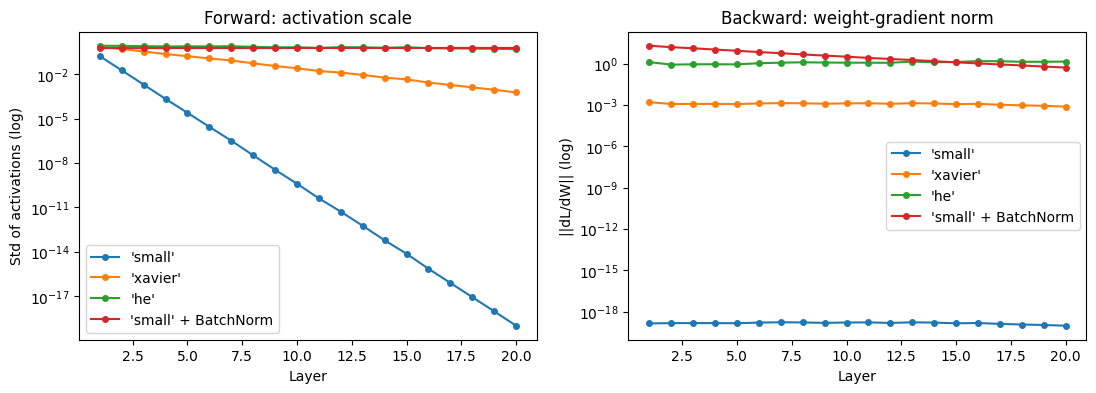

In [13]:
def deep_relu_mlp(scheme, batchnorm=False, depth=20, width=256):
    layers, d_in = [], 784
    for _ in range(depth):
        layers.append(init_linear_(nn.Linear(d_in, width), scheme))
        if batchnorm:
            layers.append(nn.BatchNorm1d(width))
        layers.append(nn.ReLU())
        d_in = width
    layers.append(init_linear_(nn.Linear(width, 10), scheme))
    return nn.Sequential(*layers)

def activation_and_grad_stats(model, X, y):
    stds, acts = [], X
    for layer in model:
        acts = layer(acts)
        if isinstance(layer, nn.ReLU):
            stds.append(acts.std().item())
    model.zero_grad()
    F.cross_entropy(model(X), y).backward()
    grad_norms = [m.weight.grad.norm().item() for m in model if isinstance(m, nn.Linear)][:-1]
    return stds, grad_norms

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
for name, kwargs in {"'small'": dict(scheme='small'), "'xavier'": dict(scheme='xavier'), "'he'": dict(scheme='he'),
                     "'small' + BatchNorm": dict(scheme='small', batchnorm=True)}.items():
    torch.manual_seed(453)
    stds, grad_norms = activation_and_grad_stats(deep_relu_mlp(**kwargs), X_train[:500], y_train[:500])
    ax1.semilogy(range(1, 21), stds, 'o-', ms=4, label=name)
    ax2.semilogy(range(1, 21), grad_norms, 'o-', ms=4, label=name)
ax1.set(xlabel='Layer', ylabel='Std of activations (log)', title='Forward: activation scale')
ax2.set(xlabel='Layer', ylabel='||dL/dW|| (log)', title='Backward: weight-gradient norm')
ax1.legend(); ax2.legend()
plt.show()

**What this shows**
- **`'he'`:** in the left plot, the line stays flat near 1 across all 20 layers, so the signal keeps its size.
- **`'xavier'`:** a straight downward line on the log scale, ending about 1,000× smaller at layer 20 than at layer 1. Every layer shrinks the signal by the same factor (about 0.7).
- **`'small'`:** drops to about $10^{-19}$, so the deep layers' outputs no longer depend on the input at all.
- **Right plot:** the gradients follow the same ranking. With `'small'` they are about $10^{-19}$ at *every* layer, so training would barely move any weight.
- **`'small' + BatchNorm`:** stays near 1, like `'he'`, even though its weights are just as tiny as `'small'`. BatchNorm rescales each layer's pre-activations (before the ReLU) back to unit variance.

Why: each ReLU layer multiplies the signal's standard deviation by $\sqrt{\text{fan\_in}\cdot\mathrm{Var}(W)/2}$ (the $/2$ because ReLU zeroes half its inputs). He initialization, $\mathrm{Var}(W) = 2/\text{fan\_in}$, makes that factor exactly 1. Xavier gives $1/\sqrt2 \approx 0.71$ here, and `'small'` gives about $0.11$.

## Part C: Regularization (20 pts)

A two-hidden-layer MLP with 1,024 units per layer has about 1.9M parameters, more than enough to memorize all 1,000 training images, *including the randomized ones*. Memorizing those wrong labels hurts accuracy on new images. Here are three ways to fight that.

### C.1) Inverted dropout (7 pts)

In training mode, zero each element independently with probability `p` and scale the survivors by $1/(1-p)$, so the expected activation is unchanged. In eval mode (`self.training == False`, set by `model.eval()`), return the input untouched. *(Hint: `torch.rand_like(x)`.)*

In [14]:
class MyDropout(nn.Module):
    def __init__(self, p=0.5):
        super().__init__()
        self.p = p

    def forward(self, x):
        if not self.training or self.p == 0:
            return x
        mask = (torch.rand_like(x) >= self.p).to(x.dtype)    # keep with probability 1 - p
        return x * mask / (1 - self.p)

In [15]:
torch.manual_seed(0)
drop = MyDropout(p=0.3)
x = torch.ones(200, 500)
drop.train()
out = drop(x)
assert abs((out == 0).float().mean().item() - 0.3) < 0.01, "about 30% should be dropped"
assert torch.allclose(out[out != 0], torch.tensor(1 / 0.7)), "survivors should be scaled by 1/(1-p)"
assert not torch.equal(drop(x), out), "a fresh mask should be drawn on each call"
drop.eval()
assert torch.equal(drop(x), x), "eval mode should be the identity"
print('looks good!')

looks good!


### C.2) Early stopping (7 pts)

Complete `EarlyStopping.step(epoch, val_loss, model)`, called once per epoch. If `val_loss` is lower than the best so far, record the loss and epoch, save a **copy** of the weights (`copy.deepcopy(model.state_dict())`), and reset the count of epochs without improvement; otherwise add one to it. Return `True` once that count reaches `patience`.

In [16]:
class EarlyStopping:
    def __init__(self, patience):
        self.patience = patience
        self.best_loss, self.best_epoch, self.best_state = float('inf'), None, None
        self.bad_epochs = 0

    def step(self, epoch, val_loss, model):
        if val_loss < self.best_loss:
            self.best_loss, self.best_epoch = val_loss, epoch
            self.best_state = copy.deepcopy(model.state_dict())
            self.bad_epochs = 0
        else:
            self.bad_epochs += 1
        return self.bad_epochs >= self.patience

In [17]:
model = nn.Linear(1, 1, bias=False)
stopper = EarlyStopping(patience=3)
for epoch, loss in enumerate([1.0, 0.8, 0.7, 0.75, 0.72, 0.71, 0.65], start=1):
    with torch.no_grad():
        model.weight.fill_(epoch)                     # tag the weights with their epoch
    if stopper.step(epoch, loss, model):
        break
assert epoch == 6, "with patience=3, it should say stop at epoch 6"
assert stopper.best_epoch == 3 and stopper.best_loss == 0.7, "the best epoch should be epoch 3"
assert stopper.best_state['weight'].item() == 3.0, "best_state should hold a copy of the weights from the best epoch"
again = EarlyStopping(patience=2)
assert [again.step(e, l, model) for e, l in enumerate([3.0, 2.0, 2.5, 1.0, 1.5, 1.2], start=1)] == \
    [False] * 5 + [True], "an improvement should reset the count"
print('looks good!')

looks good!


### C.3) An L2 penalty (6 pts)

Fill in the `# <your code>` line in `train_mlp()` so that, when `l2_lambda > 0`, the loss adds $\lambda \sum_l \lVert W^{(l)} \rVert^2$ over the **weight matrices only** (not the biases). *(Hint: in `model.named_parameters()`, weight names end in `'weight'`.)* The rest of `train_mlp()` is given. It doesn't actually stop early: it trains all 60 epochs so you can see what happens afterward, and uses your `EarlyStopping` to remember the best weights and the epoch where it *would* have stopped.

In [18]:
def make_mlp(dropout=0.0, hidden=1024):
    return nn.Sequential(
        nn.Linear(784, hidden), nn.ReLU(), MyDropout(dropout),
        nn.Linear(hidden, hidden), nn.ReLU(), MyDropout(dropout),
        nn.Linear(hidden, 10),
    )

@torch.no_grad()
def evaluate(model, X, y):
    model.eval()
    logits = model(X)
    model.train()
    return (logits.argmax(dim=1) == y).float().mean().item(), F.cross_entropy(logits, y).item()

def train_mlp(model, epochs=60, lr=1e-3, batch_size=64, l2_lambda=0.0, patience=10, seed=453):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    g = torch.Generator().manual_seed(seed)
    history = {'train_acc': [], 'val_acc': [], 'val_loss': [], 'stop_epoch': None}
    stopper = EarlyStopping(patience)
    for epoch in range(1, epochs + 1):
        model.train()
        idx = torch.randperm(len(X_train), generator=g)
        for start in range(0, len(X_train), batch_size):
            b = idx[start:start + batch_size]
            loss = F.cross_entropy(model(X_train[b]), y_train[b])
            if l2_lambda > 0:
                loss = loss + l2_lambda * sum((p ** 2).sum() for name, p in model.named_parameters() if name.endswith('weight'))
            opt.zero_grad()
            loss.backward()
            opt.step()
        history['train_acc'].append(evaluate(model, X_train, y_train)[0])
        val_acc, val_loss = evaluate(model, X_val, y_val)
        history['val_acc'].append(val_acc)
        history['val_loss'].append(val_loss)
        if stopper.step(epoch, val_loss, model) and history['stop_epoch'] is None:
            history['stop_epoch'] = epoch
    history['best_epoch'], history['best_state'] = stopper.best_epoch, stopper.best_state
    return history

In [19]:
def weight_norm_after_one_epoch(l2_lambda):
    torch.manual_seed(0)
    model = make_mlp()
    train_mlp(model, epochs=1, l2_lambda=l2_lambda)
    return sum((p ** 2).sum().item() for n, p in model.named_parameters() if n.endswith('weight'))

assert weight_norm_after_one_epoch(1e-2) < weight_norm_after_one_epoch(0.0), "the L2 penalty doesn't seem to be applied"
print('looks good!')

looks good!


### C.4) Run the experiments

**No modification required.** This trains three models for 60 epochs (under a minute on a CPU): no regularization, dropout, and an L2 penalty. It marks each model's best epoch (dashed) and where early stopping would stop (dotted), prints a summary, and then evaluates the best model on the test set once.

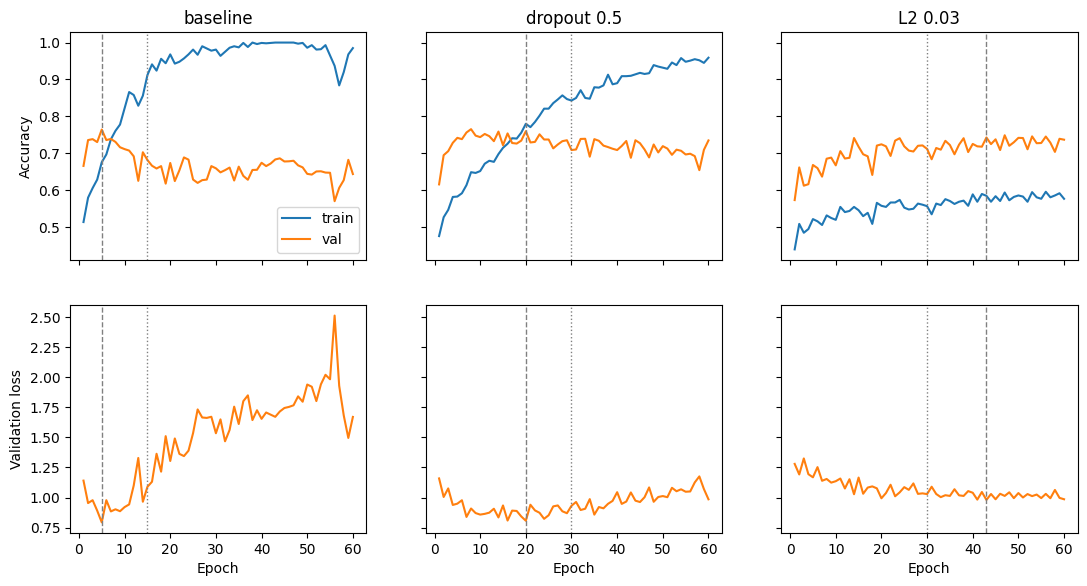

              train acc  val acc, last 5 epochs  val acc at best epoch
baseline          98.5%                   62.6%                  76.5%
dropout 0.5       95.9%                   69.8%                  76.0%
L2 0.03           57.7%                   73.1%                  74.3%
best config: baseline (epoch 5) | test accuracy 75.6%, test loss 0.823


In [20]:
experiments = {
    'baseline':    dict(dropout=0.0, l2_lambda=0.0),
    'dropout 0.5': dict(dropout=0.5, l2_lambda=0.0),
    'L2 0.03':     dict(dropout=0.0, l2_lambda=0.03),
}
histories = {}
for name, cfg in experiments.items():
    torch.manual_seed(453)
    histories[name] = train_mlp(make_mlp(dropout=cfg['dropout']), l2_lambda=cfg['l2_lambda'])

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharex=True, sharey='row')
for col, (name, h) in enumerate(histories.items()):
    epochs = range(1, len(h['val_loss']) + 1)
    axes[0, col].plot(epochs, h['train_acc'], label='train')
    axes[0, col].plot(epochs, h['val_acc'], label='val')
    axes[1, col].plot(epochs, h['val_loss'], color='C1')
    for row in range(2):
        axes[row, col].axvline(h['best_epoch'], color='gray', ls='--', lw=1)
        if h['stop_epoch']:
            axes[row, col].axvline(h['stop_epoch'], color='gray', ls=':', lw=1)
    axes[0, col].set_title(name)
    axes[1, col].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Accuracy'); axes[1, 0].set_ylabel('Validation loss')
axes[0, 0].legend()
plt.show()

print(f"{'':12s} {'train acc':>10s} {'val acc, last 5 epochs':>23s} {'val acc at best epoch':>22s}")
for name, h in histories.items():
    print(f"{name:12s} {100 * h['train_acc'][-1]:9.1f}% {100 * sum(h['val_acc'][-5:]) / 5:22.1f}% "
          f"{100 * h['val_acc'][h['best_epoch'] - 1]:21.1f}%")

best = min(histories, key=lambda name: min(histories[name]['val_loss']))
final_model = make_mlp(dropout=experiments[best]['dropout'])
final_model.load_state_dict(histories[best]['best_state'])
test_acc, test_loss = evaluate(final_model, X_test, y_test)
print(f"best config: {best} (epoch {histories[best]['best_epoch']}) | test accuracy {100 * test_acc:.1f}%, test loss {test_loss:.3f}")

**What this shows**
- **Baseline:** validation accuracy peaks at about 76% around epoch 5, then falls to about 68% while training accuracy climbs to 100%. Reaching 100% means the network has memorized the wrong labels too, and that makes it *worse* on new images. Its validation loss (bottom) shows the same thing even more sharply.
- **Dropout:** the network memorizes more slowly (training accuracy ends near 95%) and finishes about 2 points above the baseline: about 71% vs. 68% over the last 5 epochs.
- **L2:** training accuracy stays near 58%, *below* validation accuracy. The penalty keeps the weights too small to memorize the wrong labels, so the network fits only the pattern shared by the correct ones. It finishes at about 73%, the best of the three after 60 epochs.
- **Early stopping (dashed and dotted lines):** the baseline at its best epoch (about 76%) beats every model's final accuracy. Simply stopping before memorization starts is the biggest win here. If a dotted line comes *before* its dashed line (this can happen for L2), that model's validation loss stalled for 10 epochs and then improved again, which is the risk of a patience that's too short.
- **Printed line:** the model is picked by its lowest validation *loss*, the same criterion early stopping uses. That isn't necessarily the one with the highest validation accuracy in the table above. Only then is it evaluated on the test set, once. Its test accuracy should be close to its validation accuracy.

Attribution: Ben Lengerich